# Sigmoid Kernel

In [1]:
import pandas as pd
import numpy as np
from sklearn.svm import SVC
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

X_train = pd.read_csv("mnist_training.csv", header= None, ).values
y_train = pd.read_csv("mnist_train_class.csv", header= None).values.ravel()
X_test = pd.read_csv("mnist_testing.csv", header= None).values
y_test = pd.read_csv("mnist_test_class.csv", header= None).values.ravel()

print(f"Train shape: {X_train.shape},Labels: {y_train.shape}")
print(f"Test shape:  {X_test.shape},Labels: {y_test.shape}")



Train shape: (60000, 784),Labels: (60000,)
Test shape:  (10000, 784),Labels: (10000,)


# Using SVM with sigmoid kernel and Visualize Decision boundary
Instead of using all data, the code takes a random subset of 5,000 images. Just to show how it would ultimately work, as using the whole data would take more time


Training on random subset of 5000 samples

Test Accuracy: 93.76%

Classification Report: 
              precision    recall  f1-score   support

           0       0.95      0.98      0.97       980
           1       0.96      0.99      0.97      1135
           2       0.95      0.91      0.93      1032
           3       0.92      0.94      0.93      1010
           4       0.91      0.96      0.93       982
           5       0.93      0.89      0.91       892
           6       0.93      0.97      0.95       958
           7       0.95      0.92      0.94      1028
           8       0.94      0.90      0.92       974
           9       0.93      0.89      0.91      1009

    accuracy                           0.94     10000
   macro avg       0.94      0.94      0.94     10000
weighted avg       0.94      0.94      0.94     10000

Number of Support Vectors found: 32


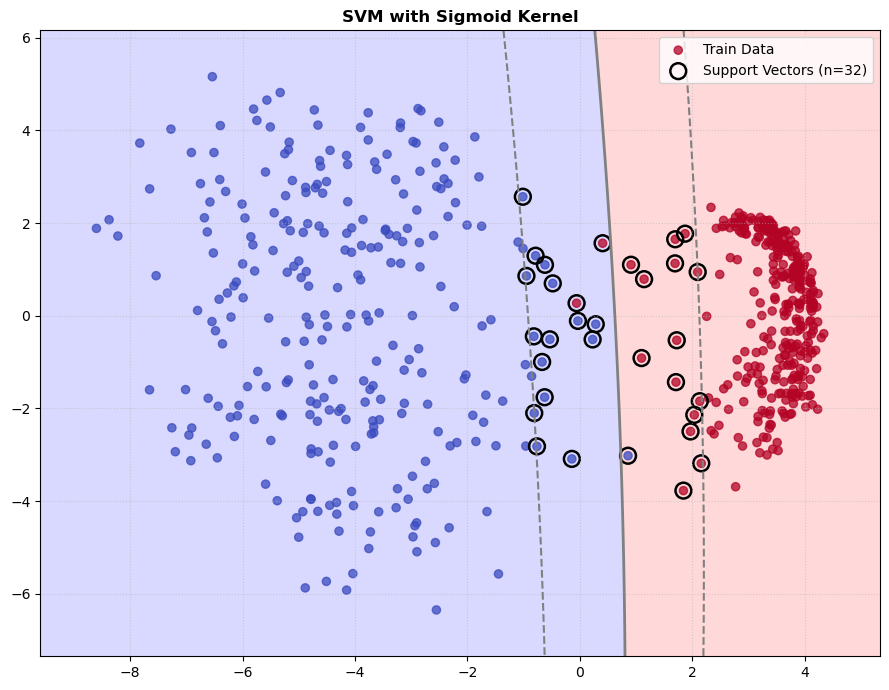

In [5]:
SUBSET_SIZE = 5000

if SUBSET_SIZE is not None and SUBSET_SIZE < len(X_train):
    np.random.seed(42)
    indices = np.random.choice(len(X_train), size =SUBSET_SIZE, replace = False)
    X_train_sub = X_train[indices]
    y_train_sub = y_train[indices]
    print(f"Training on random subset of {SUBSET_SIZE} samples")
else:
    X_train_sub = X_train
    y_train_sub = y_train
    
#SCALE DATA
X_train_scaled = (255.0 - X_train_sub) / 255.0
X_test_scaled = (255.0 - X_test) / 255.0

#TRAIN SVM WITH SIGMOID KERNEL
svm_sigmoid = SVC(
    kernel = 'sigmoid',
    C = 5.0,
    gamma = 0.005,
    coef0 = -1.0,
    random_state = 42
)

svm_sigmoid.fit(X_train_scaled, y_train_sub)

#EVALUATE ON TEST SET
y_pred = svm_sigmoid.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print(f"\nTest Accuracy: {accuracy * 100:.2f}%\n")

print("Classification Report: ")
print(classification_report(y_test,y_pred, zero_division = 0))

# VISUALIZE THE DESICION BOUNDARY
binary_mask = (y_train_sub == 0) | (y_train_sub == 1)
X_sub = X_train_scaled[binary_mask][:600]
y_sub = y_train_sub[binary_mask][:600]

# Project from 784 pixels down to 2 dimensions via PCA
pca = PCA(n_components=2, random_state=42)
X_train_2d = pca.fit_transform(X_sub)

# Fit Sigmoid SVM on the 2D projected data
svm_2d = SVC(
    kernel='sigmoid',
    C=5.0,
    gamma=0.01,
    coef0=-1.0,
    random_state=42
)
svm_2d.fit(X_train_2d, y_sub)

# Extract Support Vector coordinates
svs = X_train_2d[svm_2d.support_]
print(f"Number of Support Vectors found: {len(svs)}")

# Plotting the 2D mesh, boundary, margins, and SVs
plt.figure(figsize=(9, 7))

x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

# Decision function values (Z=0 is boundary; Z=-1 and +1 are margins)
Z = svm_2d.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

# Draw decision regions and contour lines
plt.contourf(xx, yy, Z, levels=[-100, 0, 100], alpha=0.15, colors=['blue', 'red'])
plt.contour(xx, yy, Z, levels=[-1, 0, 1], linestyles=['--', '-', '--'], colors='gray', linewidths=[1.5, 2.0, 1.5])

# Plot training samples
plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_sub, cmap='coolwarm', s=35, alpha=0.75, label='Train Data')


plt.scatter(
    svs[:, 0], svs[:, 1],
    s=130,
    facecolors='none',
    edgecolors='black',
    linewidths=1.8,
    label=f'Support Vectors (n={len(svs)})'
)

plt.title("SVM with Sigmoid Kernel", fontsize=12, fontweight='bold')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()